# Imputación de faltantes de HAire2 (2020-2021)

Este notebook realiza la imputación de valores faltantes de la variable **HAire2** con un enfoque de **Random Forest para series de tiempo**.

## Objetivo
1. Reconstruir la serie diaria completa por estación.  
2. Identificar los días faltantes.  
3. Crear variables temporales y rezagos.  
4. Entrenar un modelo de Random Forest con los datos observados.  
5. Validar la imputación ocultando bloques conocidos.  
6. Imputar los faltantes reales y exportar la base final.

> En este archivo el faltante real aparece en la estación **KENNEDY**.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", None)


## 1. Cargar archivo

In [2]:
ruta = "HAire2.csv"   # Ajusta esta ruta si el archivo está en otra carpeta
df = pd.read_csv(ruta)

df["Fecha inicial"] = pd.to_datetime(df["Fecha inicial"], errors="coerce")
df = df.sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

print("Dimensión:", df.shape)
display(df.head())


Dimensión: (1455, 4)


,Estacion,Fecha inicial,Fecha final,HAire2
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,NaN,70.125000
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,NaN,67.041667
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,NaN,66.833333
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,NaN,66.041667
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,NaN,68.083333


## 2. Reconstruir serie diaria completa

Aquí construimos una malla diaria completa entre la fecha mínima y máxima del archivo para cada estación.
Así podemos detectar explícitamente los días faltantes.


In [3]:
rango_fechas = pd.date_range(df["Fecha inicial"].min(), df["Fecha inicial"].max(), freq="D")
estaciones = sorted(df["Estacion"].dropna().unique())

base_completa = (
    pd.MultiIndex.from_product([estaciones, rango_fechas], names=["Estacion", "Fecha inicial"])
    .to_frame(index=False)
)

base = base_completa.merge(
    df[["Estacion", "Fecha inicial", "HAire2"]],
    on=["Estacion", "Fecha inicial"],
    how="left"
)

base["Fue_faltante"] = base["HAire2"].isna()

faltantes_resumen = (
    base.groupby("Estacion")
    .agg(
        registros=("HAire2", "count"),
        faltantes=("Fue_faltante", "sum")
    )
    .reset_index()
)
faltantes_resumen["porcentaje_faltante"] = (
    faltantes_resumen["faltantes"] / len(rango_fechas) * 100
)

display(faltantes_resumen)

dias_faltantes = base.loc[base["Fue_faltante"], ["Estacion", "Fecha inicial"]].copy()
display(dias_faltantes)


,Estacion,registros,faltantes,porcentaje_faltante
0,CENTRO DE ALTO RENDIMIENTO,731,0,0.000000
1,KENNEDY,724,7,0.957592


,Estacion,Fecha inicial
1231,KENNEDY,2021-05-15
1232,KENNEDY,2021-05-16
1233,KENNEDY,2021-05-17
1275,KENNEDY,2021-06-28
1276,KENNEDY,2021-06-29
1277,KENNEDY,2021-06-30
1278,KENNEDY,2021-07-01


## 3. Funciones para crear variables predictoras

Se crean:

- variables de calendario  
- variables cíclicas seno/coseno  
- rezagos de la misma serie  
- medias móviles históricas  
- valor de la otra estación el mismo día


In [4]:
def crear_features(df_long):
    x = df_long.copy().sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

    # Valor de la otra estación el mismo día
    piv = x.pivot(index="Fecha inicial", columns="Estacion", values="HAire2")
    for estacion in x["Estacion"].unique():
        otras = [c for c in piv.columns if c != estacion]
        if len(otras) == 1:
            serie_otras = piv[otras[0]]
        else:
            serie_otras = piv[otras].mean(axis=1)

        mask = x["Estacion"] == estacion
        x.loc[mask, "otra_estacion_mismo_dia"] = x.loc[mask, "Fecha inicial"].map(serie_otras)

    # Variables de calendario
    x["year"] = x["Fecha inicial"].dt.year
    x["month"] = x["Fecha inicial"].dt.month
    x["day"] = x["Fecha inicial"].dt.day
    x["dow"] = x["Fecha inicial"].dt.dayofweek
    x["weekofyear"] = x["Fecha inicial"].dt.isocalendar().week.astype(int)
    x["dayofyear"] = x["Fecha inicial"].dt.dayofyear

    # Codificación cíclica
    x["sin_doy"] = np.sin(2 * np.pi * x["dayofyear"] / 365.25)
    x["cos_doy"] = np.cos(2 * np.pi * x["dayofyear"] / 365.25)
    x["sin_dow"] = np.sin(2 * np.pi * x["dow"] / 7)
    x["cos_dow"] = np.cos(2 * np.pi * x["dow"] / 7)

    # Rezagos
    for lag in [1, 2, 3, 7, 14]:
        x[f"lag_{lag}"] = x.groupby("Estacion")["HAire2"].shift(lag)

    # Estadísticos móviles históricos
    for ventana in [3, 7, 14]:
        x[f"roll_mean_{ventana}"] = (
            x.groupby("Estacion")["HAire2"]
            .transform(lambda s: s.shift(1).rolling(ventana, min_periods=1).mean())
        )
        x[f"roll_std_{ventana}"] = (
            x.groupby("Estacion")["HAire2"]
            .transform(lambda s: s.shift(1).rolling(ventana, min_periods=2).std())
        )

    return x


feature_cols = [
    "otra_estacion_mismo_dia", "year", "month", "day", "dow", "weekofyear", "dayofyear",
    "sin_doy", "cos_doy", "sin_dow", "cos_dow",
    "lag_1", "lag_2", "lag_3", "lag_7", "lag_14",
    "roll_mean_3", "roll_std_3", "roll_mean_7", "roll_std_7", "roll_mean_14", "roll_std_14"
]


## 4. Entrenamiento del modelo de imputación

In [5]:
def entrenar_modelo(df_long):
    feat = crear_features(df_long)
    obs = feat[feat["HAire2"].notna()].copy()

    X = obs[feature_cols].copy()
    X = pd.concat([X, pd.get_dummies(obs["Estacion"], prefix="est")], axis=1)

    # Convertir a numérico y completar vacíos de predictores
    X = X.apply(pd.to_numeric, errors="coerce")
    medianas = X.median(numeric_only=True)
    X = X.fillna(medianas).infer_objects(copy=False)

    y = obs["HAire2"].astype(float).values

    modelo = RandomForestRegressor(
        n_estimators=500,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    )
    modelo.fit(X, y)

    columnas_modelo = X.columns.tolist()
    return modelo, medianas, columnas_modelo


## 5. Imputación recursiva

Esto es importante porque algunos faltantes están en bloques consecutivos.
Por eso, a medida que el modelo predice un día faltante, ese valor predicho puede servir como rezago para el siguiente día.


In [6]:
def imputar_rf_recursivo(df_long):
    actual = df_long.copy().sort_values(["Estacion", "Fecha inicial"]).reset_index(drop=True)

    modelo, medianas, columnas_modelo = entrenar_modelo(actual)

    for _ in range(10):
        feat = crear_features(actual)
        faltantes = feat[feat["HAire2"].isna()].sort_values(["Estacion", "Fecha inicial"])

        if faltantes.empty:
            break

        for idx, fila in faltantes.iterrows():
            X_fila = fila[feature_cols].to_frame().T
            dummies = pd.get_dummies(pd.Series([fila["Estacion"]]), prefix="est")
            X_fila = pd.concat([X_fila.reset_index(drop=True), dummies.reset_index(drop=True)], axis=1)

            for col in columnas_modelo:
                if col not in X_fila.columns:
                    X_fila[col] = 0

            X_fila = X_fila[columnas_modelo]
            X_fila = X_fila.apply(pd.to_numeric, errors="coerce")
            X_fila = X_fila.fillna(medianas).infer_objects(copy=False)

            pred = float(modelo.predict(X_fila)[0])
            actual.at[idx, "HAire2"] = pred

    return actual


## 6. Validación con bloques artificialmente ocultos

Antes de imputar los faltantes reales, probamos el método ocultando bloques de días conocidos en **KENNEDY**.
Eso permite medir qué tan bien reconstruye la serie.


In [7]:
def validar_por_bloques(base_original):
    bloques = [
        ("2021-03-10", 3),
        ("2021-09-05", 4),
        ("2020-07-15", 3),
        ("2020-11-20", 4),
    ]

    resultados = []
    comparaciones = []

    for fecha_inicio, longitud in bloques:
        fecha_inicio = pd.Timestamp(fecha_inicio)
        fechas_bloque = pd.date_range(fecha_inicio, periods=longitud, freq="D")

        temp = base_original.copy()

        mask = (
            (temp["Estacion"] == "KENNEDY") &
            (temp["Fecha inicial"].isin(fechas_bloque))
        )

        reales = temp.loc[mask, ["Fecha inicial", "HAire2"]].sort_values("Fecha inicial").copy()

        if reales["HAire2"].isna().any() or len(reales) != longitud:
            continue

        temp.loc[mask, "HAire2"] = np.nan
        imputado = imputar_rf_recursivo(temp)

        pred = imputado.loc[
            (imputado["Estacion"] == "KENNEDY") &
            (imputado["Fecha inicial"].isin(fechas_bloque)),
            ["Fecha inicial", "HAire2"]
        ].sort_values("Fecha inicial")

        comp = reales.merge(pred, on="Fecha inicial", suffixes=("_real", "_pred"))
        comp["bloque"] = f"{fecha_inicio.date()}_{longitud}d"

        mae = mean_absolute_error(comp["HAire2_real"], comp["HAire2_pred"])
        rmse = np.sqrt(mean_squared_error(comp["HAire2_real"], comp["HAire2_pred"]))

        resultados.append({
            "bloque": f"{fecha_inicio.date()}_{longitud}d",
            "MAE": mae,
            "RMSE": rmse
        })
        comparaciones.append(comp)

    resultados_df = pd.DataFrame(resultados)
    comparaciones_df = pd.concat(comparaciones, ignore_index=True) if comparaciones else pd.DataFrame()

    return resultados_df, comparaciones_df


resultados_validacion, comparaciones_validacion = validar_por_bloques(base)
display(resultados_validacion)

if not resultados_validacion.empty:
    print("MAE promedio:", resultados_validacion["MAE"].mean())
    print("RMSE promedio:", resultados_validacion["RMSE"].mean())


,bloque,MAE,RMSE
0,2021-03-10_3d,3.718462,3.773188
1,2021-09-05_4d,1.503851,2.214330
2,2020-07-15_3d,1.631704,1.715681
3,2020-11-20_4d,1.980693,3.031954


MAE promedio: 2.2086775344809895
RMSE promedio: 2.68378810055874


## 7. Imputación final de los faltantes reales

In [8]:
base_imputada = imputar_rf_recursivo(base)

resultado_final = base.copy()
resultado_final = resultado_final.merge(
    base_imputada[["Estacion", "Fecha inicial", "HAire2"]].rename(columns={"HAire2": "HAire2_imputado"}),
    on=["Estacion", "Fecha inicial"],
    how="left"
)

resultado_final["HAire2_original"] = resultado_final["HAire2"]
resultado_final["HAire2_final"] = np.where(
    resultado_final["Fue_faltante"],
    resultado_final["HAire2_imputado"],
    resultado_final["HAire2_original"]
)

resultado_final["Fuente_valor"] = np.where(
    resultado_final["Fue_faltante"],
    "Imputado_RF",
    "Original"
)

tabla_imputados = resultado_final.loc[
    resultado_final["Fue_faltante"],
    ["Estacion", "Fecha inicial", "HAire2_final", "Fuente_valor"]
].copy()

display(tabla_imputados)


,Estacion,Fecha inicial,HAire2_final,Fuente_valor
1231,KENNEDY,2021-05-15,60.567796,Imputado_RF
1232,KENNEDY,2021-05-16,65.119920,Imputado_RF
1233,KENNEDY,2021-05-17,68.655292,Imputado_RF
1275,KENNEDY,2021-06-28,61.030422,Imputado_RF
1276,KENNEDY,2021-06-29,52.780650,Imputado_RF
1277,KENNEDY,2021-06-30,53.618392,Imputado_RF
1278,KENNEDY,2021-07-01,65.696878,Imputado_RF


## 8. Visualización de los tramos imputados

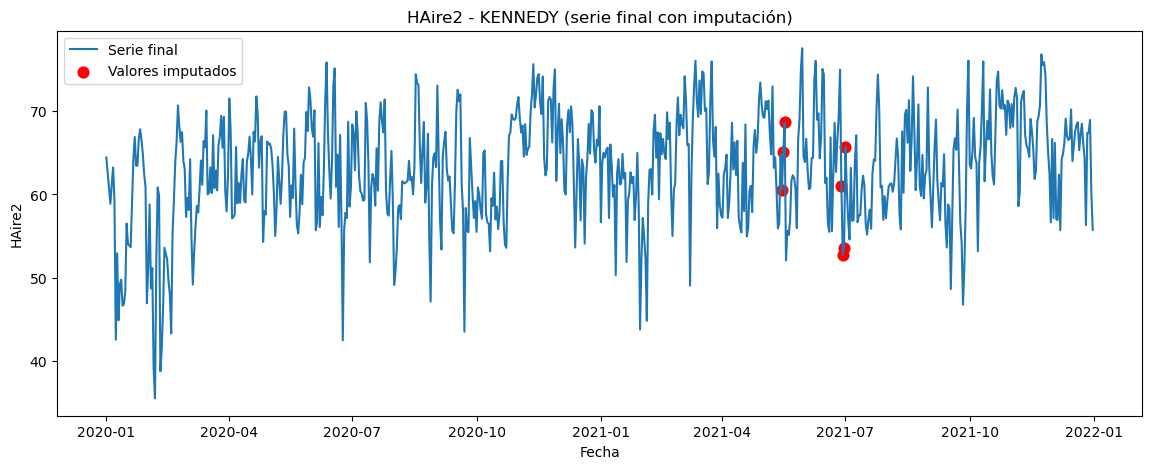

In [9]:
kennedy = resultado_final[resultado_final["Estacion"] == "KENNEDY"].copy()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(kennedy["Fecha inicial"], kennedy["HAire2_final"], label="Serie final")
ax.scatter(
    kennedy.loc[kennedy["Fue_faltante"], "Fecha inicial"],
    kennedy.loc[kennedy["Fue_faltante"], "HAire2_final"],
    s=60,
    color="Red",
    label="Valores imputados"
)
ax.set_title("HAire2 - KENNEDY (serie final con imputación)")
ax.set_xlabel("Fecha")
ax.set_ylabel("HAire2")
ax.legend()
plt.show()


## 9. Exportar dataset completo (ambas estaciones, originales e imputados)

In [10]:
# Asegurar columna Fecha final para mantener la estructura del archivo original
if "Fecha final" not in resultado_final.columns:
    resultado_final["Fecha final"] = ""

# Dataset detallado: conserva original, imputado y final
resultado_exportar_detallado = resultado_final[
    [
        "Estacion",
        "Fecha inicial",
        "Fecha final",
        "HAire2_original",
        "HAire2_imputado",
        "HAire2_final",
        "Fue_faltante",
        "Fuente_valor",
    ]
].copy()

resultado_exportar_detallado["Fecha final"] = resultado_exportar_detallado["Fecha final"].fillna("")
resultado_exportar_detallado = (
    resultado_exportar_detallado
    .sort_values(["Estacion", "Fecha inicial"])
    .reset_index(drop=True)
)

# Dataset final: listo para análisis/modelado
resultado_exportar_final = resultado_exportar_detallado[
    ["Estacion", "Fecha inicial", "Fecha final", "HAire2_final", "Fue_faltante", "Fuente_valor"]
].rename(columns={"HAire2_final": "HAire2"})

# Solo filas imputadas
tabla_imputados_exportar = resultado_exportar_detallado.loc[
    resultado_exportar_detallado["Fue_faltante"],
    [
        "Estacion",
        "Fecha inicial",
        "Fecha final",
        "HAire2_original",
        "HAire2_imputado",
        "HAire2_final",
        "Fuente_valor",
    ],
].copy()

# Exportaciones
resultado_exportar_detallado.to_csv("HAire2_dataset_completo_imputado_detallado.csv", index=False)
resultado_exportar_final.to_csv("HAire2_dataset_completo_final.csv", index=False)
tabla_imputados_exportar.to_csv("HAire2_valores_imputados.csv", index=False)

with pd.ExcelWriter("HAire2_dataset_completo_imputado_detallado.xlsx", engine="openpyxl") as writer:
    resultado_exportar_detallado.to_excel(writer, sheet_name="detalle_completo", index=False)
    resultado_exportar_final.to_excel(writer, sheet_name="dataset_final", index=False)
    tabla_imputados_exportar.to_excel(writer, sheet_name="solo_imputados", index=False)

print("Archivos exportados correctamente:")
print("- HAire2_dataset_completo_imputado_detallado.csv")
print("- HAire2_dataset_completo_final.csv")
print("- HAire2_valores_imputados.csv")
print("- HAire2_dataset_completo_imputado_detallado.xlsx")

display(resultado_exportar_detallado.head())
display(tabla_imputados_exportar)

Archivos exportados correctamente:
- HAire2_dataset_completo_imputado_detallado.csv
- HAire2_dataset_completo_final.csv
- HAire2_valores_imputados.csv
- HAire2_dataset_completo_imputado_detallado.xlsx


,Estacion,Fecha inicial,Fecha final,HAire2_original,HAire2_imputado,HAire2_final,Fue_faltante,Fuente_valor
0,CENTRO DE ALTO RENDIMIENTO,2020-01-01,,70.125000,70.125000,70.125000,False,Original
1,CENTRO DE ALTO RENDIMIENTO,2020-01-02,,67.041667,67.041667,67.041667,False,Original
2,CENTRO DE ALTO RENDIMIENTO,2020-01-03,,66.833333,66.833333,66.833333,False,Original
3,CENTRO DE ALTO RENDIMIENTO,2020-01-04,,66.041667,66.041667,66.041667,False,Original
4,CENTRO DE ALTO RENDIMIENTO,2020-01-05,,68.083333,68.083333,68.083333,False,Original


,Estacion,Fecha inicial,Fecha final,HAire2_original,HAire2_imputado,HAire2_final,Fuente_valor
1231,KENNEDY,2021-05-15,,NaN,60.567796,60.567796,Imputado_RF
1232,KENNEDY,2021-05-16,,NaN,65.119920,65.119920,Imputado_RF
1233,KENNEDY,2021-05-17,,NaN,68.655292,68.655292,Imputado_RF
1275,KENNEDY,2021-06-28,,NaN,61.030422,61.030422,Imputado_RF
1276,KENNEDY,2021-06-29,,NaN,52.780650,52.780650,Imputado_RF
1277,KENNEDY,2021-06-30,,NaN,53.618392,53.618392,Imputado_RF
1278,KENNEDY,2021-07-01,,NaN,65.696878,65.696878,Imputado_RF


## 10. Lectura metodológica final

La exportación se dejó en dos niveles:

- **Dataset detallado**: conserva el valor original, el valor imputado, el valor final, la bandera de faltante y la fuente del dato.
- **Dataset final**: deja una sola columna `HAire2` lista para análisis, conservando la trazabilidad con `Fue_faltante` y `Fuente_valor`.
- **Archivo de solo imputados**: resume únicamente las fechas que fueron completadas por el modelo.

Con esto queda una base reproducible, auditable y lista para integrarse con otras variables meteorológicas o con el contaminante objetivo.